# S05a: Avellaneda–Lee residual mean reversion (15-minute bars, sector-ETF factor)

Pre-registration: [`S05a_README.md`](S05a_README.md). Engine: `src/equity_trading/s05.py`.

Every S&P 500 stock is traded on the residual of its 15m returns against its GICS sector ETF (20-session window, re-estimated daily), with the paper's s-score rules: open at ±1.25, close long above −0.50, close short below +0.75. Stock leg 1% of equity, β-hedged in the ETF (hedges netted), up to 100 positions, 2 bps per fill.

In [1]:
N_PLACEBO = 500            # gates are defined for 1000
N_JOBS = -1

import json, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, s04, s05
from equity_trading.alpaca import ALPACA_VERSION, download_years
from equity_trading.data import work_dir

SYNTHETIC = os.environ.get("S05_SYNTHETIC") == "1"
YEARS = list(range(2020, 2026))                      # 2026 not used
CFG = s05.S05Config(n_placebo=N_PLACEBO)
if SYNTHETIC:
    YEARS, N_PLACEBO = [2024, 2025], 20

tag = ("synthetic_" if SYNTHETIC else "") + f"etf_alpaca{ALPACA_VERSION}_s05{s05.S05_VERSION}_p{s04.PANEL_VERSION}"
OUT = ROOT / "notebooks" / "Residual_Reversion" / ("05a_synthetic" if SYNTHETIC else "05a")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "s05a" / tag
CACHE.mkdir(parents=True, exist_ok=True)
PANEL_CACHE = s04.panel_cache_path(CFG.timeframe)   # shared across studies, keyed on PANEL_VERSION

COL = {"strategy": "#2a78d6", "timing": "#1baf7a", "cost2": "#eb6834", "grey": "#8a8a84"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})

if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    SECTOR = {s: k for k, v in UNIVERSE_01.items() for s in v}
    ETF_OF = {s: SECTOR_ETF_01[k] for s, k in SECTOR.items()}
    BENCH = "XLK"
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
    BENCH = "SPY"
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | stocks={len(STOCKS)} | ETFs={ETFS} | placebos={N_PLACEBO}")
print(CFG)

synthetic=False | stocks=503 | ETFs=['XLB', 'XLC', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLRE', 'XLU', 'XLV', 'XLY'] | placebos=500
S05Config(timeframe='15Min', ffill_bars=2, window_sessions=20, min_bar_share=0.95, max_tau_frac=0.5, center_m=True, open_long=-1.25, open_short=1.25, close_long=-0.5, close_short=0.75, size_per_stock=0.01, max_positions=100, initial_equity=100000.0, half_spread_bps=2.0, cost_mult=1.0, n_placebo=500, seed=42)


## 1. Data: stocks, sector ETFs, benchmark

In [2]:
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
else:
    download_years(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, workers=8)
    panel = s04.cached_panel(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, ffill_bars=CFG.ffill_bars)   # shared, versioned panel cache
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
print(f"panel {panel.c.shape} ({panel.n_days} sessions) in {time.time() - t0:.0f}s | traded stocks {len(TRADED)} | "
      f"missing: {sorted(set(STOCKS + ETFS) - have)}")
display(pd.Series([ETF_OF[s] for s in TRADED]).value_counts().rename("stocks per ETF").to_frame().T)

15Min: 0 batches to download (0 symbol-years), 8 parallel requests
panel (39064, 513) (1508 sessions) in 26s | traded stocks 501 | missing: ['FDXF', 'HONA']


,XLI,XLF,XLK,XLV,XLY,XLP,XLU,XLRE,XLB,XLC,XLE
stocks per ETF,81,76,73,59,47,34,31,30,25,24,21


## 2. Daily estimation: β, OU parameters, tradable stocks

estimated in 31s


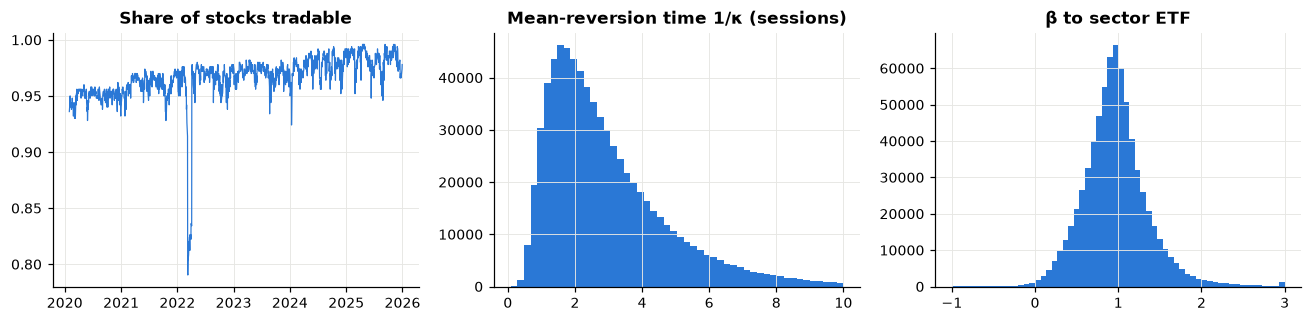

{'tradable_share_mean': 0.966, 'tau_median_sessions': 2.48, 'beta_median': 0.95}


In [3]:
FIRST = s05.first_decision_day(CFG)
est_path = CACHE / "params.npz"
if est_path.exists():
    P = dict(np.load(est_path))
else:
    t0 = time.time()
    P = s05.estimate_all(panel, SC, EC, CFG, FIRST)
    np.savez(est_path, **P); print(f"estimated in {time.time() - t0:.0f}s")
days = pd.to_datetime(panel.days)
live = slice(FIRST, panel.n_days - 1)
valid_share = pd.Series(P["valid"][live].mean(axis=1), index=days[live])
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(valid_share, color=COL["strategy"], lw=0.8); ax[0].set_title("Share of stocks tradable")
tau_d = P["tau"][live][P["valid"][live]] / 26
ax[1].hist(np.clip(tau_d, 0, 10), bins=50, color=COL["strategy"]); ax[1].set_title("Mean-reversion time 1/κ (sessions)")
ax[2].hist(np.clip(P["beta"][live][P["valid"][live]], -1, 3), bins=60, color=COL["strategy"]); ax[2].set_title("β to sector ETF")
plt.tight_layout(); plt.show()
print({"tradable_share_mean": round(float(valid_share.mean()), 3), "tau_median_sessions": round(float(np.median(tau_d)), 2),
       "beta_median": round(float(np.median(P["beta"][live][P["valid"][live]])), 2)})

## 3. Strategy backtest (1×, 2× and 0× cost)

3 backtests in 23s; trading starts 2020-02-03


,total_return,sharpe,max_drawdown,mean_daily,days
1x cost,0.0531,0.1908,0.1178,0.0000,1486.0
2x cost,-0.2723,-0.8271,0.2839,-0.0002,1486.0
0x cost,0.5462,1.2200,0.1122,0.0003,1486.0


,strategy 1x
trades,59033.0000
trades_per_day,39.6994
win_rate_gross,0.6261
mean_gross_bps,7.9258
median_bars,49.0000
gross_pnl,42225.7188
total_cost,36916.2266
cost_share_of_gross,0.0381
avg_open_positions,99.8053
avg_gross_exposure_pct,126.6587


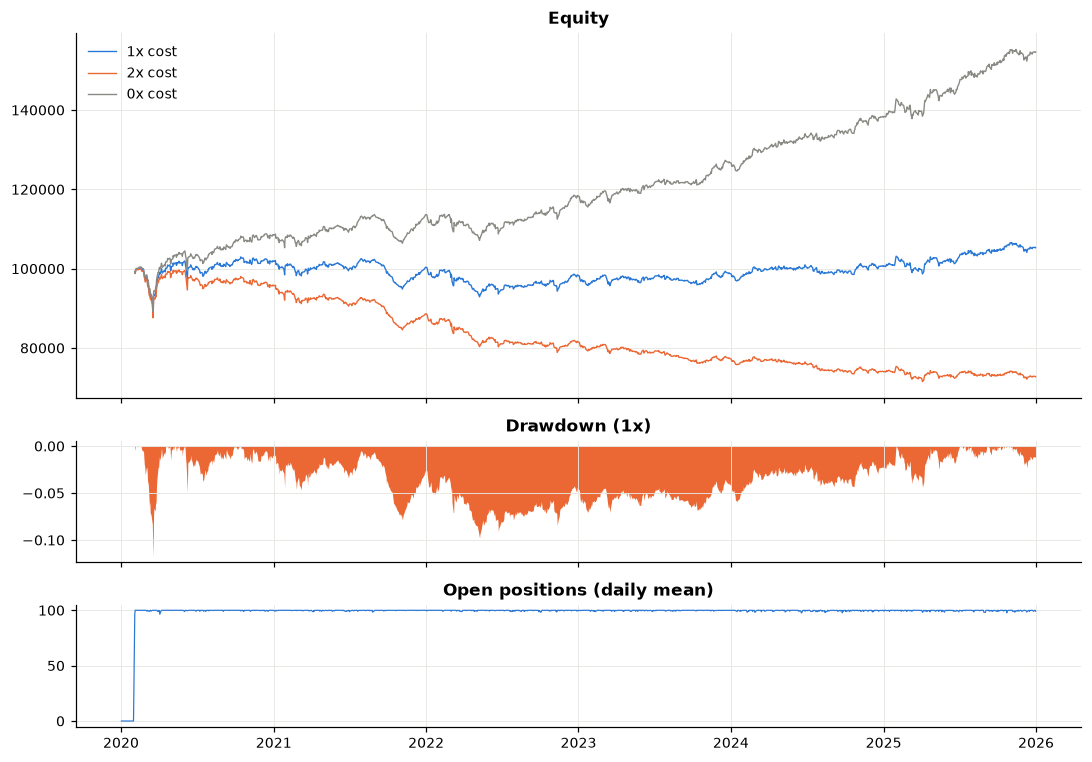

In [4]:
from dataclasses import replace
t0 = time.time()
runs = {m: s05.backtest(panel, P, SC, EC, replace(CFG, cost_mult=m), record=(m == 1.0)) for m in (1.0, 2.0, 0.0)}
base = runs[1.0]
START = base["first_day"]
print(f"3 backtests in {time.time() - t0:.0f}s; trading starts {START.date()}")
metrics = pd.DataFrame({f"{m:g}x cost": s04.perf_metrics(r["daily_equity"], CFG.initial_equity, START) for m, r in runs.items()})
display(metrics.T.round(4))

trades = base["trades"].copy()
trades["symbol"] = [TRADED[i] for i in trades["i"]]
tstats = {"trades": int(len(trades)), "trades_per_day": float(len(trades) / max(1, (days >= START).sum())),
          "win_rate_gross": float((trades.gross_pnl > 0).mean()), "mean_gross_bps": float(1e4 * trades.gross_ret.mean()),
          "median_bars": float(trades.bars.median()), "gross_pnl": float(trades.gross_pnl.sum()),
          "total_cost": float(base["total_cost"]), "cost_share_of_gross": float(base["total_cost"] / max(trades.gross_pnl.abs().sum(), 1e-9)),
          "avg_open_positions": float(base["n_open"][panel.day_start[FIRST + 1]:].mean()),
          "avg_gross_exposure_pct": float(100 * np.mean(base["gross_exposure"][panel.day_start[FIRST + 1]:] /
                                                        base["bar_equity"].to_numpy()[panel.day_start[FIRST + 1]:]))}
display(pd.Series(tstats).round(4).to_frame("strategy 1x"))
trades.drop(columns=["i"]).to_csv(OUT / "trades.csv", index=False, float_format="%.6g")
base["daily_equity"].to_csv(OUT / "daily_equity.csv", header=["equity"], float_format="%.2f")

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]})
for m, r in runs.items():
    e = r["daily_equity"][r["daily_equity"].index >= START]
    ax[0].plot(e.index, e, lw=0.9, label=f"{m:g}x cost", color={1.0: COL["strategy"], 2.0: COL["cost2"], 0.0: COL["grey"]}[m])
ax[0].set_title("Equity"); ax[0].legend(frameon=False)
e = base["daily_equity"][base["daily_equity"].index >= START]
ax[1].fill_between(e.index, e / e.cummax() - 1, 0, color=COL["cost2"], lw=0); ax[1].set_title("Drawdown (1x)")
no = pd.Series(base["n_open"], index=panel.index)
ax[2].plot(no.groupby(no.index.date).mean(), color=COL["strategy"], lw=0.8); ax[2].set_title("Open positions (daily mean)")
plt.tight_layout(); plt.show()

In [5]:
by_year = trades.assign(year=pd.DatetimeIndex(trades.entry_time).year).groupby("year").agg(
    trades=("gross_pnl", "size"), gross_pnl=("gross_pnl", "sum"), mean_gross_bps=("gross_ret", lambda x: 1e4 * x.mean()))
eq_y = base["daily_equity"][base["daily_equity"].index >= START]
year_end = eq_y.groupby(eq_y.index.year).last()
by_year["net_return"] = year_end / year_end.shift(1).fillna(CFG.initial_equity) - 1
display(by_year.round(4))
s_b = pd.cut(trades.s_entry.abs(), [1.25, 1.5, 2.0, 3.0, np.inf], include_lowest=True)
display(trades.groupby(s_b, observed=True).agg(n=("gross_pnl", "size"), mean_gross_bps=("gross_ret", lambda x: 1e4 * x.mean())).round(2))
print("most traded:", trades.symbol.value_counts().head(10).to_dict())

,trades,gross_pnl,mean_gross_bps,net_return
year,,,,
2020,9905,8164.7099,9.3492,0.0193
2021,9843,4963.4072,5.7625,-0.0150
2022,9871,3342.7042,3.7201,-0.0201
2023,9644,6249.9017,7.1395,0.0047
2024,10069,8625.1853,9.4982,0.0175
2025,9701,10879.8105,12.0965,0.0471


,n,mean_gross_bps
s_entry,,
"(1.249, 1.5]",576,35.14
"(1.5, 2.0]",12366,8.61
"(2.0, 3.0]",35359,6.76
"(3.0, inf]",10732,9.52


most traded: {'NTRS': 157, 'KMB': 150, 'KDP': 150, 'FITB': 147, 'GOOG': 144, 'CL': 143, 'WY': 143, 'XOM': 142, 'BRO': 142, 'NOW': 142}


## 4. Placebos: random direction (same trades) and random contrarian timing

random direction: {'observed_gross': 42225.7188, 'p_upper': 0.0001, 'percentile': 100.0, 'placebo_p95': 10732.0743}


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 136 tasks      | elapsed:  6.2min
[Parallel(n_jobs=-1)]: Done 316 tasks      | elapsed: 14.6min
[Parallel(n_jobs=-1)]: Done 500 out of 500 | elapsed: 23.7min finished


500 timing placebos in 23.7 min
strategy entry rate used by P-timing: 0.3752


,value,percentile,p_upper,placebo_median,placebo_p95
total_return,0.0531,83.0,0.1717,0.0276,0.0728
sharpe,0.1908,85.6,0.1457,0.1176,0.2357


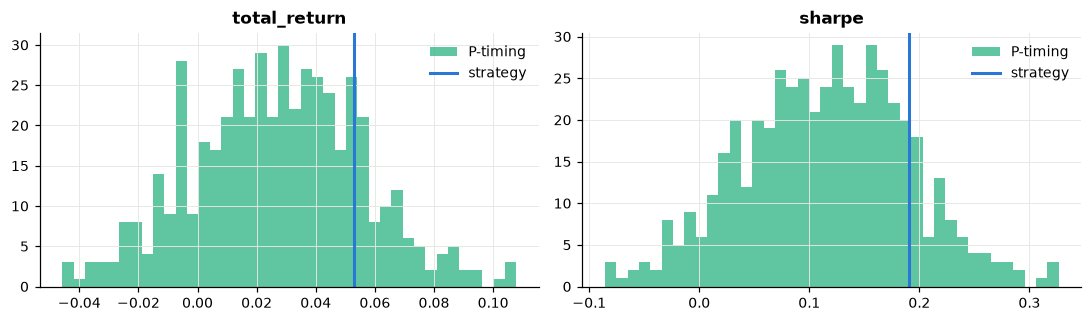

In [6]:
from joblib import Parallel, delayed
rand_dir = s05.random_direction_test(trades.gross_pnl.to_numpy(), n=10_000, seed=CFG.seed)
print("random direction:", {k: round(v, 4) for k, v in rand_dir.items()})

pl_path = CACHE / f"placebo_timing_{N_PLACEBO}.parquet"
if pl_path.exists():
    placebo = pd.read_parquet(pl_path)
else:
    t0 = time.time()
    placebo = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=2, verbose=5)(
        delayed(s05.run_placebo)(panel, P, SC, EC, CFG, base["entry_rate"], CFG.seed * 1000 + i, START) for i in range(N_PLACEBO)))
    placebo.to_parquet(pl_path); print(f"{N_PLACEBO} timing placebos in {(time.time() - t0) / 60:.1f} min")
placebo.to_csv(OUT / "placebo_timing.csv", index=False, float_format="%.6g")
bm = metrics["1x cost"]
ranks = {k: s04.placebo_rank(bm[k], placebo[k].to_numpy()) for k in ("total_return", "sharpe")}
print(f"strategy entry rate used by P-timing: {base['entry_rate']:.4f}")
display(pd.DataFrame(ranks).T.round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for i, k in enumerate(["total_return", "sharpe"]):
    ax[i].hist(placebo[k], bins=40, color=COL["timing"], alpha=0.7, label="P-timing")
    ax[i].axvline(bm[k], color=COL["strategy"], lw=2, label="strategy"); ax[i].set_title(k); ax[i].legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Bootstrap, market exposure, gates

In [7]:
r_daily = base["daily_equity"][base["daily_equity"].index >= START].pct_change().dropna().to_numpy()
boot = {b: s04.block_bootstrap_mean(r_daily, b, 10_000, CFG.seed) for b in (10, 20, 40)}
display(pd.DataFrame(boot, index=["mean", "lo95", "hi95"]).T)
bench_close = pd.Series(panel.c[panel.day_start[1:] - 1, panel.symbols.index(BENCH)], index=days)
mkt = s04.market_regression(base["daily_equity"][base["daily_equity"].index >= START], bench_close)
print("market regression vs", BENCH, {k: round(v, 5) for k, v in mkt.items()})
G = s05.gates(boot, rand_dir, ranks, metrics["2x cost"].to_dict(), metrics["1x cost"].to_dict())
display(pd.Series(G).to_frame("S05a"))

summary = {"study": "S05a", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "trading_start": str(START.date()),
           "n_placebo": N_PLACEBO, "metrics": metrics.to_dict(), "trade_stats": tstats, "random_direction": rand_dir,
           "placebo_timing_ranks": ranks, "bootstrap": {str(k): v for k, v in boot.items()}, "market": mkt, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps({k: G[k] for k in ["statistical_verdict", "economic_verdict", "verdict"]}, indent=2))

,mean,lo95,hi95
10,0.000047,-0.000150,0.000244
20,0.000047,-0.000148,0.000234
40,0.000047,-0.000084,0.000221


market regression vs SPY {'alpha_daily': 1e-05, 'alpha_p': 0.89217, 'beta': 0.05348, 'r2': 0.03193, 'n': 1486}


,S05a
G1_bootstrap,False
G2_random_direction,True
G3_vs_random_timing,False
G4_double_cost,False
statistical_verdict,PARTIAL
economic_verdict,NOT_PROFITABLE_AFTER_COSTS
verdict,NO_EDGE


{
  "statistical_verdict": "PARTIAL",
  "economic_verdict": "NOT_PROFITABLE_AFTER_COSTS",
  "verdict": "NO_EDGE"
}
